# WW REVENUE PREDICTION

In [64]:
#  Opening Weekend = Friday , Sat, Sunday

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn import metrics
 
import warnings
warnings.filterwarnings('ignore')

In [65]:
df = pd.read_csv('boxoffice_mojo_df.csv')
df.head()

,Unnamed: 0,movie,distributor,rating,genre,widest_release,opening_gross,domestic_gross,worldwide_gross,budget,main_genre,side_genre
0,0,Beverly Hills Chihuahua,Walt Disney Studios Motion Pictures,PG,Adventure Comedy Drama Family Romance,3239,29.30,94.51,149.29,20.0,Adventure,Comedy
1,1,National Treasure: Book of Secrets,Walt Disney Studios Motion Pictures,PG,Action Adventure Mystery Thriller,3832,44.78,219.96,459.24,130.0,Action,Adventure
2,2,Hannah Montana and Miley Cyrus: Best of Both W...,Walt Disney Studios Motion Pictures,G,Documentary Music,687,31.12,65.28,70.64,7.0,Documentary,Music
3,3,Step Up 2: The Streets,Walt Disney Studios Motion Pictures,PG-13,Drama Music Romance,2528,18.91,58.02,150.82,17.5,Drama,Music
4,4,The Forbidden Kingdom,Lions Gate Films,PG-13,Action Adventure Fantasy,3151,21.40,52.08,128.78,55.0,Action,Adventure


In [66]:
df.isnull().sum()

Unnamed: 0           0
movie                0
distributor          0
rating               0
genre                0
widest_release       0
opening_gross        0
domestic_gross       0
worldwide_gross      0
budget               0
main_genre           0
side_genre         178
dtype: int64

In [67]:
df[df['side_genre'].isnull()]

,Unnamed: 0,movie,distributor,rating,genre,widest_release,opening_gross,domestic_gross,worldwide_gross,budget,main_genre,side_genre
10,10,The Family That Preys,Lions Gate Films,PG-13,Drama,2070,17.38,37.11,37.11,15.0,Drama,NaN
36,36,Be Kind Rewind,New Line Cinema,PG-13,Comedy,810,4.10,11.18,30.58,20.0,Comedy,NaN
40,40,The Kite Runner,Paramount Vantage,PG-13,Drama,715,0.47,15.80,75.01,20.0,Drama,NaN
43,43,The Visitor,Overture Films,PG-13,Drama,270,0.09,9.43,18.20,4.0,Drama,NaN
46,46,Expelled: No Intelligence Allowed,Rocky Mountain Pictures,PG,Documentary,1052,2.97,7.72,7.72,12.0,Documentary,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2607,2607,Cuando sea joven,Pantelion Films,PG,Comedy,315,0.27,0.59,2.03,5.0,Comedy,NaN
2610,2610,God's Country,IFC Films,R,Thriller,785,0.28,0.49,0.49,1.5,Thriller,NaN
2611,2611,Deep in the Heart: A Texas Wildlife Story,Fin and Fur Films,PG,Documentary,69,0.13,0.48,0.48,100.0,Documentary,NaN
2617,2617,Superspreader,Iconic Events Releasing,PG-13,Documentary,235,0.29,0.40,0.40,3.0,Documentary,NaN


In [68]:
df['side_genre'].fillna('NA', inplace=True)

In [69]:
df.sample(5)

,Unnamed: 0,movie,distributor,rating,genre,widest_release,opening_gross,domestic_gross,worldwide_gross,budget,main_genre,side_genre
1194,1194,The Book of Life,Twentieth Century Fox,PG,Adventure Animation Comedy Family Fantasy Musi...,3113,17.01,50.15,99.78,50.0,Adventure,Animation
315,315,Seven Pounds,Sony Pictures Entertainment (SPE),PG-13,Drama Mystery Thriller,2758,14.85,69.95,169.75,55.0,Drama,Mystery
852,852,The Guilt Trip,Paramount Pictures,PG-13,Comedy Drama,2431,5.29,37.13,41.86,40.0,Comedy,Drama
2602,2602,The Tiger Rising,Variance Films,PG,Family,872,0.36,0.84,1.12,10.0,Family,NA
1828,1828,The Favourite,Fox Searchlight,R,Biography Comedy Drama History,1554,0.42,34.37,95.92,15.0,Biography,Comedy


In [70]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,2620.0,1309.500000,756.473176,0.000,654.7500,1309.500,1964.250,2619.00
widest_release,2620.0,2424.731298,1221.156093,5.000,1382.7500,2706.000,3375.250,4802.00
opening_gross,2620.0,18.581954,30.169281,0.010,1.3375,9.105,22.025,357.12
domestic_gross,2620.0,63.720107,94.539065,0.150,9.5975,31.760,75.630,936.66
worldwide_gross,2620.0,158.340011,261.028186,0.150,19.2325,60.330,175.655,2799.44
budget,2620.0,50.816421,58.340710,0.015,12.0000,29.000,65.000,400.00


In [71]:

# def add_opening_theaters(df):
#     df["opening_theaters"] = np.nan

#   # Apply logic based on worldwide revenue
#     for i in df.index:
#         release = df.loc[i, "widest_release"]
#         if release < 600:
#             df.loc[i, "opening_theaters"] = np.random.randint(20, 300)
       
#         else:
#             df.loc[i, "opening_theaters"] = df.loc[i, "widest_release"]

#     return df

# # Add the "opening_theaters" column
# df = add_opening_theaters(df.copy())





In [72]:
# df.to_csv('bm.csv')

In [73]:
df[df['worldwide_gross']<15]

,Unnamed: 0,movie,distributor,rating,genre,widest_release,opening_gross,domestic_gross,worldwide_gross,budget,main_genre,side_genre
31,31,The Pirates Who Don't Do Anything,Universal Pictures,G,Adventure Animation Comedy Family Fantasy,1340,4.25,12.98,13.25,15.0,Adventure,Animation
34,34,Soul Men,MGM/Weinstein,R,Comedy Drama Music,2048,5.40,12.08,12.33,40.0,Comedy,Drama
35,35,The Longshots,MGM/Weinstein,PG,Biography Comedy Drama Family Sport,2089,4.08,11.54,11.77,23.0,Biography,Comedy
42,42,Smart People,Miramax,R,Comedy Drama Romance,1119,4.09,9.51,11.84,7.0,Comedy,Drama
46,46,Expelled: No Intelligence Allowed,Rocky Mountain Pictures,PG,Documentary,1052,2.97,7.72,7.72,12.0,Documentary,NA
...,...,...,...,...,...,...,...,...,...,...,...,...
2614,2614,Eiffel,Blue Fox Entertainment,R,Biography Drama History Romance,308,0.04,0.44,13.65,25.0,Biography,Drama
2615,2615,Brian and Charles,Focus Features,PG,Comedy Drama Sci-Fi,279,0.22,0.43,0.86,100.0,Comedy,Drama
2617,2617,Superspreader,Iconic Events Releasing,PG-13,Documentary,235,0.29,0.40,0.40,3.0,Documentary,NA
2618,2618,The Inspection,A24,R,Drama,144,0.07,0.39,0.55,3.0,Drama,NA


In [74]:
to_remove = ['opening_gross', 'domestic_gross','Unnamed: 0']
df.drop(to_remove, axis=1, inplace=True)

In [75]:
df.isnull().sum() * 100 / df.shape[0]

movie              0.0
distributor        0.0
rating             0.0
genre              0.0
widest_release     0.0
worldwide_gross    0.0
budget             0.0
main_genre         0.0
side_genre         0.0
dtype: float64

In [76]:
ml_df = df.drop(columns=['movie','genre'])
ml_df.head(1)

,distributor,rating,widest_release,worldwide_gross,budget,main_genre,side_genre
0,Walt Disney Studios Motion Pictures,PG,3239,149.29,20.0,Adventure,Comedy


In [77]:
ml_df[ml_df['widest_release']<=600]

,distributor,rating,widest_release,worldwide_gross,budget,main_genre,side_genre
32,The Weinstein Company,PG-13,454,23.31,1.7,Adventure,Drama
33,Focus Features,PG-13,539,16.72,13.0,Comedy,Romance
38,Sony Pictures Classics,R,391,16.94,12.0,Drama,Romance
43,Overture Films,PG-13,270,18.20,4.0,Drama,NA
45,Focus Features,R,232,33.39,15.0,Comedy,Crime
...,...,...,...,...,...,...,...
2614,Blue Fox Entertainment,R,308,13.65,25.0,Biography,Drama
2615,Focus Features,PG,279,0.86,100.0,Comedy,Drama
2617,Iconic Events Releasing,PG-13,235,0.40,3.0,Documentary,NA
2618,A24,R,144,0.55,3.0,Drama,NA


In [78]:
# print(ml_df.shape)
# ml_df = ml_df[ml_df['widest_release']>=600]
# ml_df.shape

In [79]:
ml_df.shape

(2620, 7)

In [81]:
ml_df['distributor'].value_counts().head(60)

distributor
Warner Bros.                             303
Universal Pictures                       254
Twentieth Century Fox                    205
Lions Gate Films                         196
Sony Pictures Entertainment (SPE)        178
Walt Disney Studios Motion Pictures      170
Paramount Pictures                       160
Focus Features                           114
Fox Searchlight                           77
Sony Pictures Classics                    68
The Weinstein Company                     60
Screen Gems                               51
Roadside Attractions                      49
A24                                       49
Open Road Films (II)                      43
STX Entertainment                         38
Relativity Media                          33
Summit Entertainment                      32
Bleecker Street Media                     31
TriStar Pictures                          28
DreamWorks                                27
Neon                                      2

In [82]:
# import pandas as pd


def replace_rare_distributors(df, distributor_column, threshold=15, replacement="Other"):
    distributor_counts = df[distributor_column].value_counts()
    rare_distributors = distributor_counts[distributor_counts < threshold].index.tolist()
    df.loc[df[distributor_column].isin(rare_distributors), distributor_column] = replacement
    return df


ml_df = replace_rare_distributors(ml_df, "distributor", threshold=100)



In [83]:
ml_df['distributor'].value_counts()

distributor
Other                                  1040
Warner Bros.                            303
Universal Pictures                      254
Twentieth Century Fox                   205
Lions Gate Films                        196
Sony Pictures Entertainment (SPE)       178
Walt Disney Studios Motion Pictures     170
Paramount Pictures                      160
Focus Features                          114
Name: count, dtype: int64

In [84]:
ml_df['main_genre'].value_counts()

main_genre
Action         784
Comedy         547
Drama          406
Adventure      306
Biography      262
Horror         124
Crime          107
Documentary     43
Animation       19
Fantasy         10
Mystery          5
Thriller         2
Sci-Fi           1
Music            1
Musical          1
History          1
Family           1
Name: count, dtype: int64

In [85]:
# action_rows = ml_df[ml_df['main_genre'] == 'Action'].sample(n=100)  # Drop 2 rows (adjust n as needed)
# ml_df = ml_df.drop(action_rows.index)
# ml_df = ml_df.reset_index()

In [86]:
ml_df.head()

,distributor,rating,widest_release,worldwide_gross,budget,main_genre,side_genre
0,Walt Disney Studios Motion Pictures,PG,3239,149.29,20.0,Adventure,Comedy
1,Walt Disney Studios Motion Pictures,PG,3832,459.24,130.0,Action,Adventure
2,Walt Disney Studios Motion Pictures,G,687,70.64,7.0,Documentary,Music
3,Walt Disney Studios Motion Pictures,PG-13,2528,150.82,17.5,Drama,Music
4,Lions Gate Films,PG-13,3151,128.78,55.0,Action,Adventure


In [87]:
# ml_df.drop(columns=['index'],inplace=True)

In [88]:
def replace_rare_main_genre(df, main_genre_column, threshold=15, replacement="Other"):
    main_genre_counts = df[main_genre_column].value_counts()
    rare_main_genre = main_genre_counts[main_genre_counts < threshold].index.tolist()
    df.loc[df[main_genre_column].isin(rare_main_genre), main_genre_column] = replacement
    return df


ml_df = replace_rare_main_genre(ml_df, "main_genre", threshold=100)


In [89]:
ml_df['main_genre'].value_counts()

main_genre
Action       784
Comedy       547
Drama        406
Adventure    306
Biography    262
Horror       124
Crime        107
Other         84
Name: count, dtype: int64

In [90]:
ml_df['side_genre'].value_counts()

side_genre
Drama          653
Adventure      395
Comedy         207
Crime          182
NA             178
Romance        152
Animation      143
Mystery        143
Horror         105
Thriller        94
Fantasy         77
Family          71
Music           50
Sci-Fi          42
Biography       32
Documentary     30
History         23
Sport           13
War             10
Musical         10
Western          7
Short            3
Name: count, dtype: int64

In [91]:
# drama_rows = ml_df[ml_df['side_genre'] == 'Drama'].sample(n=100)  # Drop 2 rows (adjust n as needed)
# ml_df = ml_df.drop(drama_rows.index)
# ml_df = ml_df.reset_index()
# ml_df.drop(columns=['index'],inplace=True)

In [92]:
def replace_rare_side_genre(df, side_genre_column, threshold=15, replacement="Other"):
    side_genre_counts = df[side_genre_column].value_counts()
    rare_side_genre = side_genre_counts[side_genre_counts < threshold].index.tolist()
    df.loc[df[side_genre_column].isin(rare_side_genre), side_genre_column] = replacement
    return df


ml_df = replace_rare_side_genre(ml_df, "side_genre", threshold=50)

In [93]:
ml_df['side_genre'].value_counts()

side_genre
Drama        653
Adventure    395
Comedy       207
Crime        182
NA           178
Other        170
Romance      152
Mystery      143
Animation    143
Horror       105
Thriller      94
Fantasy       77
Family        71
Music         50
Name: count, dtype: int64

In [94]:
ml_df.head(3)

,distributor,rating,widest_release,worldwide_gross,budget,main_genre,side_genre
0,Walt Disney Studios Motion Pictures,PG,3239,149.29,20.0,Adventure,Comedy
1,Walt Disney Studios Motion Pictures,PG,3832,459.24,130.0,Action,Adventure
2,Walt Disney Studios Motion Pictures,G,687,70.64,7.0,Other,Music


In [95]:
from sklearn.preprocessing import OrdinalEncoder

# Create separate OrdinalEncoder instances for each column
oe_distributor = OrdinalEncoder(handle_unknown='use_encoded_value' , unknown_value=-1)
oe_rating = OrdinalEncoder(handle_unknown='use_encoded_value' , unknown_value=-1)
oe_mgenre = OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
oe_sgenre = OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)

# Encode each column separately
ml_df['distributor'] = oe_distributor.fit_transform(ml_df[['distributor']])
ml_df['rating'] = oe_rating.fit_transform(ml_df[['rating']])
ml_df['main_genre'] = oe_mgenre.fit_transform(ml_df[['main_genre']])
ml_df['side_genre'] = oe_sgenre.fit_transform(ml_df[['side_genre']])
print(ml_df['distributor'].nunique())
print(ml_df['rating'].nunique())
print(ml_df['main_genre'].nunique())
print(ml_df['side_genre'].nunique())

9
4
8
14


In [96]:
ml_df.head()

,distributor,rating,widest_release,worldwide_gross,budget,main_genre,side_genre
0,7.0,1.0,3239,149.29,20.0,1.0,2.0
1,7.0,1.0,3832,459.24,130.0,0.0,0.0
2,7.0,0.0,687,70.64,7.0,7.0,8.0
3,7.0,2.0,2528,150.82,17.5,5.0,8.0
4,1.0,2.0,3151,128.78,55.0,0.0,0.0


<Axes: >

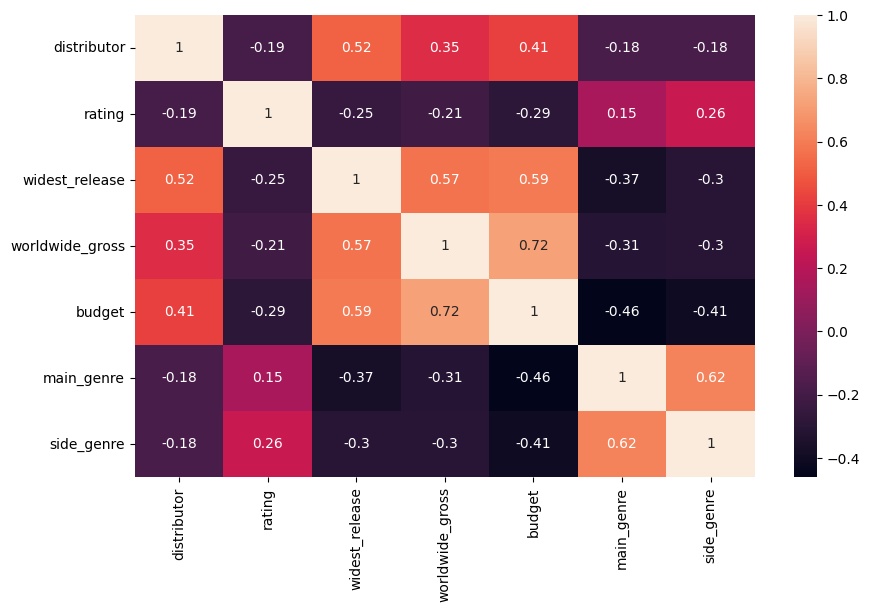

In [97]:
plt.figure(figsize=(10,6))
sns.heatmap(ml_df.corr(),annot=True)

In [57]:
from sklearn.model_selection import train_test_split

X= ml_df.drop(columns=['worldwide_gross'])
y= ml_df['worldwide_gross']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(2096, 6) (524, 6) (2096,) (524,)


In [58]:
X_test.columns

Index(['distributor', 'rating', 'widest_release', 'budget', 'main_genre',
       'side_genre'],
      dtype='object')

In [59]:
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

In [60]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.metrics import r2_score

model_rf = RandomForestRegressor()

# Train the model
model_rf.fit(X_train, y_train)

predictions = model_rf.predict(X_test)

# Evaluate the model
score = model_rf.score(X_test, y_test)

print(score)


# Calculate the R-squared score
r_squared = r2_score(y_test, predictions)

print("R squared:", round(r_squared, 2))

mae = mean_absolute_error(y_test, predictions)

print("MAE:",round(mae, 2) )


# Calculate the MSE
mse = mean_squared_error(y_test, predictions, squared=False)

print("MSE:", round(mse, 2))

0.7945618150231701
R squared: 0.79
MAE: 59.41
MSE: 114.18


In [61]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.metrics import r2_score

model_rf_g = RandomForestRegressor(max_depth=15,max_features='log2',min_samples_leaf= 2,min_samples_split= 2, n_estimators=100)

# Train the model
model_rf_g.fit(X_train, y_train)

predictions = model_rf_g.predict(X_test)

# Evaluate the model
score = model_rf_g.score(X_test, y_test)

print(score)


# Calculate the R-squared score
r_squared = r2_score(y_test, predictions)

print("R squared:", round(r_squared, 2))

mae = mean_absolute_error(y_test, predictions)

print("MAE:",round(mae, 2) )


# Calculate the MSE
mse = mean_squared_error(y_test, predictions, squared=False)

print("MSE:", round(mse, 2))

0.7594480288938692
R squared: 0.76
MAE: 62.04
MSE: 123.55


In [62]:
# from sklearn.model_selection import GridSearchCV
# from sklearn.ensemble import RandomForestRegressor

# # Define your hyperparameter grid
# param_grid = {
#     'n_estimators': [100, 200, 500,700],  # Number of trees in the forest
#     'max_depth': [5, 10, 15],  # Maximum depth of each tree
#     'min_samples_split': [2, 5, 10],  # Minimum number of samples required to split a node
#     'min_samples_leaf': [ 2, 4,8],  # Minimum number of samples required at each leaf node
#     'max_features': ['auto', 'sqrt', 'log2']  # Number of features to consider at each split
# }

# # Create your Random Forest Regressor
# rf = RandomForestRegressor()

# # Initialize the GridSearchCV object
# grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5,verbose=2)

# # Fit the GridSearchCV to your training data
# grid_search.fit(X_train, y_train)

# # Best parameters and score
# best_params = grid_search.best_params_
# best_score = grid_search.best_score_

# # Print the best parameters and score
# print("Best parameters:", best_params)
# print("Best score:", best_score)



In [63]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.metrics import r2_score

xgbr = XGBRegressor()

# Train the model
xgbr.fit(X_train, y_train)


predictions = xgbr.predict(X_test)

# Evaluate the model on the test set
# score = xgbr.score(X_test, y_test)

# print("R squared:", round(score, 2))

# Calculate the R-squared score
r_squared = r2_score(y_test, predictions)

print("R squared:", round(r_squared, 2))

mae = mean_absolute_error(y_test, predictions)

print("MAE:",round(mae, 2) )


# Calculate the MSE
mse = mean_squared_error(y_test, predictions, squared=False)

print("MSE:", round(mse, 2))

R squared: 0.78
MAE: 58.63
MSE: 118.23


In [87]:
import pickle

ml_df={'model':model_rf , 'oe_distributor':oe_distributor, 'oe_rating':oe_rating , 'oe_mgenre':oe_mgenre, 'oe_sgenre':oe_sgenre}
with open ('saved_steps_worldwide.pkl', 'wb') as file:
    pickle.dump(ml_df, file)

In [88]:
with open ('saved_steps_worldwide.pkl', 'rb') as file:
    ml_df = pickle.load(file)

regressor_loaded = ml_df['model']
oe_distributor = ml_df['oe_distributor']
oe_rating = ml_df['oe_rating']
oe_mgenre = ml_df['oe_mgenre']
oe_sgenre = ml_df['oe_sgenre']

In [89]:
# 'distributor', 'rating', 'widest_release', 'budget', 'main_genre','side_genre','opening_theaters'
x=np.array([['Universal Pictures', 'PG' , 3839,72,'Action','Adventure']])
x

array([['Universal Pictures', 'PG', '3839', '72', 'Action', 'Adventure']],
      dtype='<U18')

In [90]:
x[:,0] = oe_distributor.transform(x[:,0].reshape(-1,1))
x[:,1] = oe_rating.transform(x[:,1].reshape(-1,1))
x[:,4] = oe_mgenre.transform(x[:,4].reshape(-1,1))
x[:,5] = oe_sgenre.transform(x[:,5].reshape(-1,1))
x=x.astype(float)
x

array([[1.000e+01, 1.000e+00, 3.839e+03, 7.200e+01, 0.000e+00, 0.000e+00]])

In [91]:
y_pred= model_rf.predict(x)
y_pred

array([279.4414])

In [92]:
# 'Walt Disney Studios Motion Pictures', 'PG' , 4035,200,'Adventure','Animation' = ELEMENTAL
# 'Warner Bros.', 'PG-13' , 4337,145,'Adventure','Comedy' = BARBIE
# 'Universal Pictures', 'R' , 3761,100,'Biography','Drama' = openheimer
# 'Warner Bros.', 'PG' , 4213,125,'Adventure','Comedy' = wonka
# 'Universal Pictures', 'PG' , 4099,130,'Adventure','Animation = puss in boots
# 'Universal Pictures', 'PG' , 4343,100,'Adventure','Animation' = super mario